## BERTopic

Edgar Osvaldo Navarro Garcia A01644488

In [28]:
%pip install "datasets<4.0.0"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic
import pandas as pd


# --- PASO 1: Cargar Wikipedia en formato nativo Parquet (Sin errores de scripts) ---
print("1. Cargando artículos de Wikipedia (FineWiki - Español)...")
dataset = load_dataset("HuggingFaceFW/finewiki", name="es", streaming=True)
shuffled_dataset = dataset["train"].shuffle(buffer_size=100000, seed=42)

articles_list = []
max_articles = 25000  # 10,000 artículos de noticias es un excelente tamaño para comenzar

for i, sample in enumerate(shuffled_dataset):
    # En este dataset, el cuerpo del artículo está en la clave 'text'
    text = sample.get("text", "")
    if text:
        articles_list.append(text)
    if i >= max_articles - 1:
        break
df = pd.DataFrame({"text": articles_list})

# Limpieza básica recomendada para articulos (eliminar nulos o vacíos)
df = df.dropna(subset=["text"])
docs = df["text"].tolist()

print(f"Total de articulos cargados para modelado: {len(docs)}")

# 1. Descargar la lista de stopwords en español de NLTK
nltk.download('stopwords')
spanish_stopwords = stopwords.words('spanish')

vectorizer_model = CountVectorizer(stop_words=spanish_stopwords)

# Borramos entradas con pocas palabras y que sean duplicadas para mejorar la calidad del modelado

df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

# 1.2 Filtrar articulos con menos de 50 o más de 250 palabras
df["word_count"] = df["text"].apply(lambda x: len(str(x).split()))
df = df[df["word_count"] >= 50].reset_index(drop=True)
df = df[df["word_count"] <= 250].reset_index(drop=True)

docs = df["text"].tolist()
print(f"Total de articulos después de limpiar duplicados y < 50 o > 250 palabras: {len(docs)}")

1. Cargando artículos de Wikipedia (FineWiki - Español)...
Total de articulos cargados para modelado: 25000


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ngedg\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Total de articulos después de limpiar duplicados y < 50 o > 250 palabras: 11254


In [30]:
# Longitud promedio de los artículos
average_length = df["word_count"].mean()

--- Reporte de Longitudes del Corpus ---
Número total de segmentos (documentos válidos): 11254
Longitud promedio por segmento: 130.96 palabras

[Aviso sobre Embeddings]:
El modelo 'paraphrase-multilingual-MiniLM-L12-v2' tiene un límite operativo (típicamente 128 o 256 tokens).
Segmentos con más de 250 palabras (potencialmente truncados): 0 (0.00%)


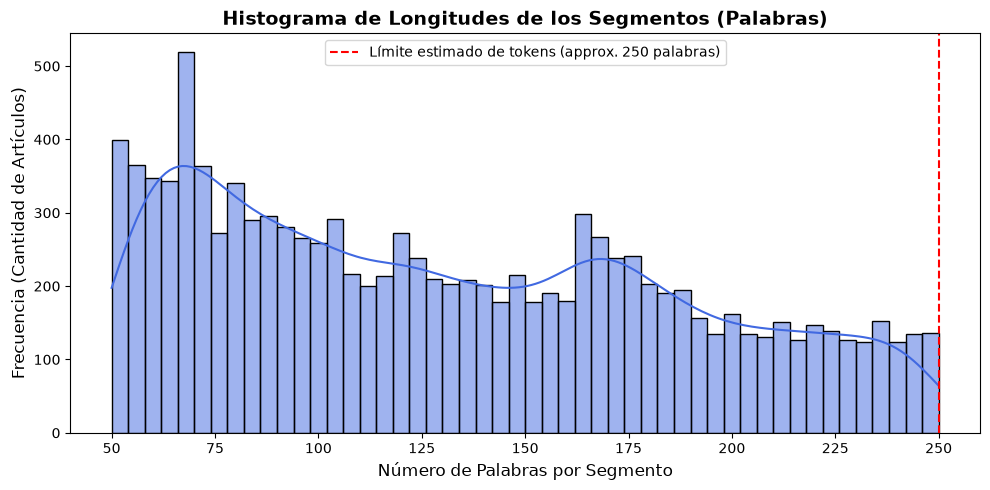

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- PASO ADICIONAL: Reporte y Estadísticas de Longitud ---
print("--- Reporte de Longitudes del Corpus ---")

# 1. Número total de segmentos
num_segments = len(docs)
print(f"Número total de segmentos (documentos válidos): {num_segments}")

# 2. Longitud promedio (en palabras)
word_counts = [len(doc.split()) for doc in docs]
avg_length = sum(word_counts) / num_segments if num_segments > 0 else 0
print(f"Longitud promedio por segmento: {avg_length:.2f} palabras")

# 3. Alerta sobre el límite del modelo de embeddings
print("\n[Aviso sobre Embeddings]:")
print("El modelo 'paraphrase-multilingual-MiniLM-L12-v2' tiene un límite operativo (típicamente 128 o 256 tokens).")
exceeding_docs = sum(1 for w in word_counts if w > 250)
print(f"Segmentos con más de 250 palabras (potencialmente truncados): {exceeding_docs} ({exceeding_docs/num_segments*100:.2f}%)")

# 4. Histograma de longitudes
plt.figure(figsize=(10, 5))
sns.histplot(word_counts, bins=50, kde=True, color='royalblue')
plt.title('Histograma de Longitudes de los Segmentos (Palabras)', fontsize=14, fontweight='bold')
plt.xlabel('Número de Palabras por Segmento', fontsize=12)
plt.ylabel('Frecuencia (Cantidad de Artículos)', fontsize=12)
plt.axvline(250, color='red', linestyle='--', label='Límite estimado de tokens (approx. 250 palabras)')
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
from umap import UMAP

print("3. Configurando UMAP con random_state fijo...")
# Fijar random_state asegura que la reducción dimensional sea idéntica en cada ejecución
umap_model = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric='cosine',
    random_state=42 
)

3. Configurando UMAP con random_state fijo...


In [33]:
print("5. Configurando HDBSCAN...")

hdbscan_model = HDBSCAN(
    min_cluster_size=50, 
    min_samples=5, 
    metric='euclidean', 
    prediction_data=True
)

5. Configurando HDBSCAN...


In [34]:
# 3. Inicializar el modelo BERTopic pasándole el vectorizador
embedding_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

embedding_model.max_seq_length = 256 

topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    nr_topics=10,             # <-- Forzar a fusionar automáticamente en 10 tópicos principales
    language="multilingual",
    calculate_probabilities=True,
    verbose=True
)


topic_model_5 = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    nr_topics=5,             # <-- Forzar a fusionar automáticamente en 5 tópicos principales
    language="multilingual",
    calculate_probabilities=True,
    verbose=True
)

# 4. Ajustar el modelo a tus documentos
topics, probabilities = topic_model.fit_transform(docs)
topics_5, probabilities_5 = topic_model_5.fit_transform(docs)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 987.45it/s]
2026-10-30 18:55:26,911 - BERTopic - Embedding - Transforming documents to embeddings.
Batches: 100%|██████████| 352/352 [00:33<00:00, 10.48it/s]
2026-10-30 18:56:00,567 - BERTopic - Embedding - Completed ✓
2026-10-30 18:56:00,568 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-30 18:56:08,472 - BERTopic - Dimensionality - Completed ✓
2026-10-30 18:56:08,478 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-30 18:56:09,692 - BERTopic - Cluster - Completed ✓
2026-10-30 18:56:09,693 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-10-30 18:56:11,513 - BERTopic - Representation - Completed ✓
2026-10-30 18:56:11,513 - BERTopic - Topic reduction - Reducing number of topics
2026-10-30 18:56:11,532 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-30 18:56:13,039 - BERTopic - Representation - C

In [35]:
# ==========================================
# 1. Mapa Genealógico / Jerarquía: 10 Tópicos
# ==========================================
print("Generando el árbol genealógico para el modelo de 10 tópicos...")
fig_h10 = topic_model.visualize_hierarchy()
fig_h10.show()

# ==========================================
# 2. Mapa Genealógico / Jerarquía: 5 Tópicos
# ==========================================
print("Generando el árbol genealógico para el modelo de 5 tópicos...")
fig_h5 = topic_model_5.visualize_hierarchy()
fig_h5.show()

Generando el árbol genealógico para el modelo de 10 tópicos...


Generando el árbol genealógico para el modelo de 5 tópicos...


In [47]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# 1. Generar las figuras individuales con BERTopic
fig_10 = topic_model.visualize_topics()
fig_5 = topic_model_5.visualize_topics()

# 2. Crear una figura contenedora con 1 fila y 2 columnas para ponerlos lado a lado
# Nota: Como visualize_topics() usa gráficos de dispersión (scatter), 
# podemos extraer sus trazas y combinarlas en una sola vista estructurada.

fig_comparativa = make_subplots(
    rows=1, cols=2, 
    subplot_titles=("Modelo: 10 Tópicos (Granularidad Alta)", "Modelo: 5 Tópicos (Granularidad General)")
)

# 3. Agregar las trazas del modelo de 10 tópicos en la primera columna
for data in fig_10['data']:
    fig_comparativa.add_trace(data, row=1, col=1)

# 4. Agregar las trazas del modelo de 5 tópicos en la segunda columna
for data in fig_5['data']:
    fig_comparativa.add_trace(data, row=1, col=2)

# 5. Actualizar el diseño general de la ventana comparativa
fig_comparativa.update_layout(
    title_text="Comparación Espacial de Tópicos (BERTopic)",
    showlegend=False,
    height=600,
    width=1200
)

# Mostrar la figura interactiva
fig_comparativa.show()

In [37]:
# 1. Calcular el número total de tópicos reales
num_topics = len(topic_model.get_topic_info()) 
print(f"Número total de tópicos detectados: {num_topics}")

# 2. Mostrar la tabla completa para ver el conteo de documentos por cada tópico
print("\n--- Resumen de Tópicos y Conteo de Documentos ---")
print(topic_model.get_topic_info())

Número total de tópicos detectados: 10

--- Resumen de Tópicos y Conteo de Documentos ---
   Topic  Count                                       Name  \
0     -1   1363                 -1_ciudad_san_parte_nombre   
1      0   4445           0_medalla_campeonato_mundial_año   
2      1   1514            1_km²_población_censo_municipio   
3      2   1271          2_especie_género_familia_especies   
4      3   1128  3_habitantes_distrito_población_encuentra   
5      4    628                  4_the_álbum_canción_banda   
6      5    402             5_displaystyle_puede_forma_ser   
7      6    321       6_ua_sol_características_descubierto   
8      7    104           7_inglaterra_unido_condado_reino   
9      8     78             8_software_sistema_linux_datos   

                                      Representation  \
0  [ciudad, san, parte, nombre, universidad, sigl...   
1  [medalla, campeonato, mundial, año, juegos, br...   
2  [km², población, censo, municipio, según, dens...   
3  

#### Mostramos los textos representativos de cada tema

In [38]:
import numpy as np

# 1. Obtener solo los tópicos únicos (excluyendo el -1 de outliers)
topicos_unicos = sorted([t for t in set(topics) if t != -1])

# 2. Iterar únicamente sobre los tópicos reales
for topico in topicos_unicos:
    print(f"\n--- Tópico {topico} (Más representativos por probabilidad) ---")
    
    # Obtener los índices de los documentos de este tópico
    indices_topico = [i for i, t in enumerate(topics) if t == topico]
    
    if indices_topico and probabilities is not None:
        # Extraer las probabilidades de estos documentos para este tópico específico
        probs_topico = [(i, probabilities[i][topico]) for i in indices_topico]
        # Ordenar de mayor a menor probabilidad
        probs_topico.sort(key=lambda x: x[1], reverse=True)
        
        # Tomar los top 2 con mayor probabilidad
        top_indices = [item[0] for item in probs_topico[:2]]
        
        for idx in top_indices:
            print(f"  - {docs[idx][:300]}...\n")


--- Tópico 0 (Más representativos por probabilidad) ---
  - # Ricardo Bravo Delgadillo
Ricardo Bravo Delgadillo (Tulancingo de Bravo, Hidalgo; 3 de abril de 1965) es un político mexicano, conocido empresario y contador, que fue presidente municipal de Tulancingo de Bravo del 2006 al 2009. En una contienda, donde por primera vez el partido en el que militaba ...

  - # Tanad Boonsuwan
Tanad Boonsuwan es un deportista tailandés que compitió en taekwondo. Ganó una medalla de bronce en el Campeonato Asiático de Taekwondo de 1982, en la categoría de –52 kg.

## Palmarés internacional
| Campeonato Asiático | Campeonato Asiático | Campeonato Asiático | Campeonato Asiá...


--- Tópico 1 (Más representativos por probabilidad) ---
  - # Discriminación por vivienda
La discriminación por vivienda es la discriminación basada en el estatus de clase protegida, considerando raza;  género; etnicidad; religión; edad; discapacidad; nacionalidad; orientación sexual, sexo o identidad de género y  estado c

In [39]:
# Calcular el porcentaje de outliers (tópico -1) en el modelo de 10 tópicos
num_outliers = topics.count(-1)

print(f"\nNúmero de outliers (tópico -1): {num_outliers}")
print(f"Porcentaje de outliers: {num_outliers / len(topics) * 100:.2f}%")


Número de outliers (tópico -1): 1363
Porcentaje de outliers: 12.11%


In [40]:
# 1. Calcular el número total de tópicos reales
num_topics = len(topic_model_5.get_topic_info())
print(f"Número total de tópicos detectados: {num_topics}")

# 2. Mostrar la tabla completa para ver el conteo de documentos por cada tópico
print("\n--- Resumen de Tópicos y Conteo de Documentos ---")
print(topic_model_5.get_topic_info())

Número total de tópicos detectados: 5

--- Resumen de Tópicos y Conteo de Documentos ---
   Topic  Count                                  Name  \
0     -1   1363            -1_ciudad_san_parte_nombre   
1      0   6746      0_medalla_campeonato_año_mundial   
2      1   2746      1_población_km²_habitantes_censo   
3      2    321  2_ua_sol_características_descubierto   
4      3     78        3_software_sistema_datos_linux   

                                      Representation  \
0  [ciudad, san, parte, nombre, universidad, prov...   
1  [medalla, campeonato, año, mundial, juegos, br...   
2  [población, km², habitantes, censo, municipio,...   
3  [ua, sol, características, descubierto, órbita...   
4  [software, sistema, datos, linux, puede, siste...   

                                 Representative_Docs  
0  [# Grassano\nGrassano es un municipio situado ...  
1  [# Geremia Di Constanzo\nGeremia Di Constanzo ...  
2  [# Municipio de Washington (condado de Sevier)...  
3  [# (3000

In [41]:
import numpy as np

# 1. Obtener solo los tópicos únicos para el modelo de 5 (excluyendo el -1)
topicos_unicos_5 = sorted([t for t in set(topics_5) if t != -1])

# 2. Iterar únicamente sobre cada tópico real
for topico in topicos_unicos_5:
    print(f"\n--- Tópico {topico} (Más representativos por probabilidad) ---")
    
    # Obtener los índices de los documentos de este tópico
    indices_topico = [i for i, t in enumerate(topics_5) if t == topico]
    
    if indices_topico and probabilities_5 is not None:
        # Extraer las probabilidades de estos documentos para este tópico específico
        probs_topico = [(i, probabilities_5[i][topico]) for i in indices_topico]
        # Ordenar de mayor a menor probabilidad
        probs_topico.sort(key=lambda x: x[1], reverse=True)
        
        # Tomar los top 3 con mayor probabilidad
        top_indices = [item[0] for item in probs_topico[:3]]
        
        for idx in top_indices:
            print(f"  - {docs[idx][:300]}...\n")


--- Tópico 0 (Más representativos por probabilidad) ---
  - # Ricardo Bravo Delgadillo
Ricardo Bravo Delgadillo (Tulancingo de Bravo, Hidalgo; 3 de abril de 1965) es un político mexicano, conocido empresario y contador, que fue presidente municipal de Tulancingo de Bravo del 2006 al 2009. En una contienda, donde por primera vez el partido en el que militaba ...

  - # Tanad Boonsuwan
Tanad Boonsuwan es un deportista tailandés que compitió en taekwondo. Ganó una medalla de bronce en el Campeonato Asiático de Taekwondo de 1982, en la categoría de –52 kg.

## Palmarés internacional
| Campeonato Asiático | Campeonato Asiático | Campeonato Asiático | Campeonato Asiá...

  - # Bipirámide pentagonal
En geometría, la bipirámide pentagonal es la tercera del conjunto infinito de bipirámides isoédricas. 
Las distintas bipirámides son los duales de los respectivos prismas uniformes.
Si las caras son triángulos equiláteros, también se trata de un sólido de Johnson (J13). Puede...


--- Tópico 1 (M

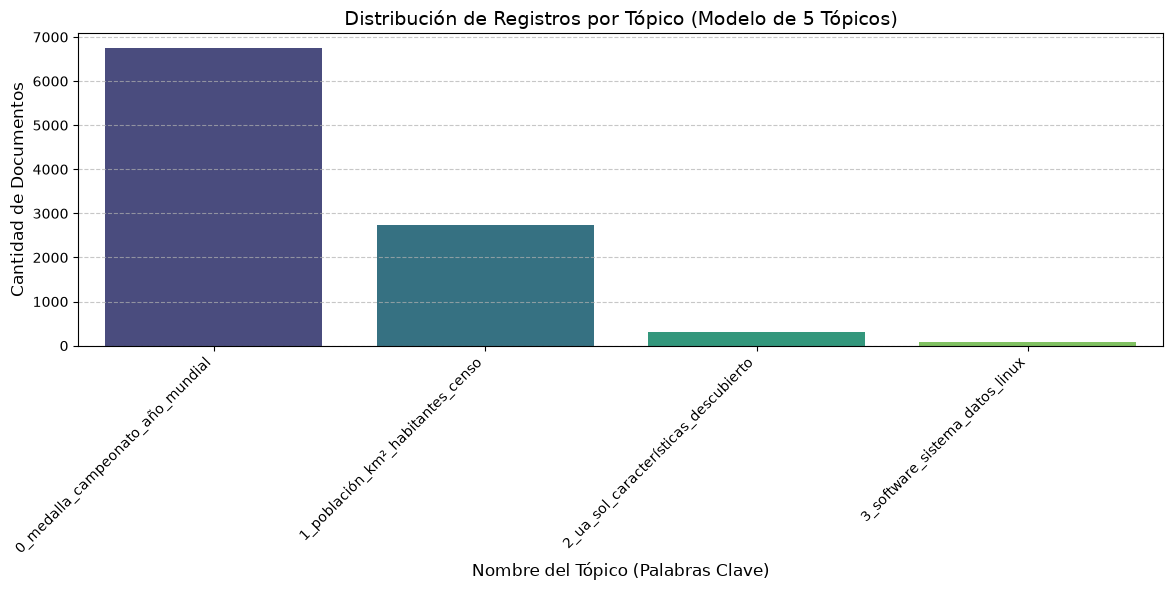

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Obtener la tabla de información de los tópicos del modelo de 5
df_info = topic_model_5.get_topic_info()

# Excluir el tópico -1 (outliers) para enfocarnos únicamente en los temas principales
df_info_clean = df_info[df_info['Topic'] != -1]

# 2. Crear la gráfica de barras usando el nombre del tópico en el eje X
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_info_clean, 
    x='Name', 
    y='Count', 
    palette='viridis'
)

plt.title('Distribución de Registros por Tópico (Modelo de 5 Tópicos)', fontsize=14)
plt.xlabel('Nombre del Tópico (Palabras Clave)', fontsize=12)
plt.ylabel('Cantidad de Documentos', fontsize=12)

# Rotar las etiquetas del eje X para que no se encimen y se lean bien
plt.xticks(rotation=45, ha='right')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Mostrar la gráfica
plt.show()

#### Tratamiento de outliers

A los outliers se ejecutara bertopic otra vez para obtener otros 5 temas

In [43]:
# 1. Crear un HDBSCAN más permisivo y específico para los outliers
hdbscan_model_outliers = HDBSCAN(
    min_cluster_size=15,  # Reducido de 40 a 15 para capturar subtemas más pequeños
    min_samples=5,
    metric='euclidean',
    prediction_data=True,
)

In [44]:
# 1. Extraer los textos y los índices de los documentos que son outliers en tu modelo de 5
outlier_indices = [i for i, t in enumerate(topics_5) if t == -1]
outlier_docs = [docs[i] for i in outlier_indices]

print(
    f"Número de documentos en outliers (-1) a re-analizar: {len(outlier_docs)}"
)

# 2. Instanciar un nuevo modelo BERTopic exclusivo para estos outliers
topic_model_outliers = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model_outliers,
    vectorizer_model=vectorizer_model,
    nr_topics=3,  # <-- Forzar exactamente  nuevos temas para este subconjunto
    language="multilingual",
    calculate_probabilities=True,
    verbose=True,
)

# 3. Ajustar el nuevo modelo únicamente con los documentos de ruido
topics_sub, probabilities_sub = topic_model_outliers.fit_transform(outlier_docs)

# 4. Ver el resumen de estos nuevos 5 temas encontrados en el ruido
print("\n--- Nuevos Tópicos encontrados dentro de los Outliers ---")
print(topic_model_outliers.get_topic_info())

2026-10-30 18:57:14,570 - BERTopic - Embedding - Transforming documents to embeddings.


Número de documentos en outliers (-1) a re-analizar: 1363


Batches: 100%|██████████| 43/43 [00:04<00:00,  9.85it/s]
2026-10-30 18:57:18,948 - BERTopic - Embedding - Completed ✓
2026-10-30 18:57:18,948 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-30 18:57:22,788 - BERTopic - Dimensionality - Completed ✓
2026-10-30 18:57:22,798 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-30 18:57:22,895 - BERTopic - Cluster - Completed ✓
2026-10-30 18:57:22,895 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-10-30 18:57:23,250 - BERTopic - Representation - Completed ✓
2026-10-30 18:57:23,252 - BERTopic - Topic reduction - Reducing number of topics
2026-10-30 18:57:23,252 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-30 18:57:23,556 - BERTopic - Representation - Completed ✓
2026-10-30 18:57:23,556 - BERTopic - Topic reduction - Reduced number of topics from 30 to 3



--- Nuevos Tópicos encontrados dentro de los Outliers ---
   Topic  Count                                       Name  \
0     -1    420                  -1_ciudad_san_parte_siglo   
1      0    829            0_ciudad_universidad_san_nombre   
2      1    114  1_población_habitantes_distrito_encuentra   

                                      Representation  \
0  [ciudad, san, parte, siglo, dos, nombre, año, ...   
1  [ciudad, universidad, san, nombre, parte, años...   
2  [población, habitantes, distrito, encuentra, m...   

                                 Representative_Docs  
0  [# Corneilla-del-Vercol\nCorneilla-del-Vercol ...  
1  [# Taloto\nTaloto es un barrio rural   del mun...  
2  [# Gornja Jagodnja\nGornja Jagodnja es una loc...  


In [45]:
import numpy as np

# 1. Obtener solo los tópicos únicos del modelo de outliers (excluyendo el -1 por si quedó algo de ruido residual)
topicos_unicos_sub = sorted([t for t in set(topics_sub) if t != -1])

# 2. Iterar sobre cada nuevo sub-tópico encontrado en los outliers
for topico in topicos_unicos_sub:
    print(f"\n--- Sub-Tópico {topico} (Extraído del ruido) ---")
    
    # Obtener los índices de los documentos de este sub-tópico dentro de la lista 'outlier_docs'
    indices_topico = [i for i, t in enumerate(topics_sub) if t == topico]
    
    if indices_topico and probabilities_sub is not None:
        # Extraer las probabilidades de estos documentos para este sub-tópico específico
        probs_topico = [(i, probabilities_sub[i][topico]) for i in indices_topico]
        # Ordenar de mayor a menor probabilidad
        probs_topico.sort(key=lambda x: x[1], reverse=True)
        
        # Tomar los top 2 con mayor probabilidad
        top_indices = [item[0] for item in probs_topico[:2]]
        
        for idx in top_indices:
            print(f"  - {outlier_docs[idx][:300]}...\n")


--- Sub-Tópico 0 (Extraído del ruido) ---
  - # Clase Quebec
El Proyecto 615 (nombre en código de la OTAN Quebec) fue una clase de submarinos costeros de ataque de la Unión Soviética.

## Descripción
Los submarinos de la clase Quebec estaban equipados con 1 motor eléctrico, 2 motores diésel y 1 motor diésel de ciclo cerrado, el cual funcionaba ...

  - # Tanner Fletcher
Tanner Fletcher es una marca de moda sin género basada en Brooklyn, Nueva York. Fue fundada en 2020 por Tanner Richie y Fletcher Kasell.La marca fusiona siluetas tradicionales con estéticas modernas, utilizando telas y adornos similares a los tapizados inspirados en los muebles de ...


--- Sub-Tópico 1 (Extraído del ruido) ---
  - # Táp
Táp es un pueblo húngaro perteneciente al condado de Győr-Moson-Sopron, distrito de Pannonhalma.

## Superficie
Cuenta con una superficie de 19,88 kilómetros cuadrados.

## Demografía
Hasta 2023 la población era de 718 habitantes, con una densidad de población de 36,11 habitantes por k

In [46]:
print(embedding_model.max_seq_length)

256
